# Which drift correction for the 1 Nov 2026 outlook?

Summary of `nov2026_outlook/01`-`06` in four results.

**Background.** After it is started, the model drifts away from the observed climate. Forecast anomalies are
therefore taken relative to a *lead-time dependent climatology*: the observed climatology plus the model's
average drift at that lead, measured from the Reanalysis hindcasts (1981-2018 starts, 24 months long). The
choices below decide most of the La Niña outlook.

| term | meaning |
|---|---|
| **MDC** (current approach) | drift = average over the hindcast starts (currently 1981-2010) |
| **TrDC** (Kharin et al. 2012) | drift = average + a linear trend over the start years |
| **ICDC** (Fučkar et al. 2014) | drift = average + a term depending on the starting El Niño/La Niña state |
| **year 3, factor $r$** | the hindcasts stop after 2 years; year 3 of the 2026 forecast repeats the year-2 drift ($r = 0$, current) or adds the year-1-to-2 change once more ($r = 1$) |
| **free-running large ensemble (LE)** | 25 E3SMv3 historical simulations, same model configuration, never initialised from observations: the model's own climate, which a hindcast approaches once it has forgotten its start |

**The four results:**
1. The drift grows with the start year, because the model warms Niño3.4 and the real world does not → a fixed average is wrong; use a trend.
2. Tested on starts it has not seen, only the trend correction (TrDC) forecasts better than the current one.
3. In year 3 the drift is still changing (the hindcasts are still moving away from the model's own climate) → continue it, $r = 1$.
4. Result for 2026: P(La Niña 2027/28) ≈ 0.8, P(La Niña 2028/29) ≈ 0.5, against 0.3 and 0.17 now.

In [1]:
%matplotlib inline
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import load_netcdf

NOTEBOOK = "nov2026_outlook/07_drift_correction_decision"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/07_drift_correction_decision/{figures,data}/
INIT = 11
ADJUST_LEADS = 3
N_BOOT = 1000
# caches of 04 (hindcast members, all start months) and 06 (large ensemble); saved results of 01-06
HC_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift", "nino34_trop_members_init02050811_ref1981-2018_y2026_l36_HadISST1.1_v1.nc")
LE_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift", "nino34_trop_v3LR_historical_m25_y1980-2034_v1.nc")
RES = {n: rc.output_dir(f"nov2026_outlook/{n}", "data") for n in (
    "01_year3_drift_sensitivity", "03_drift_trend_and_test", "04_start_months_and_year3_test",
    "05_drift_correction_methods", "06_year3_drift_asymptote")}
DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def read(nb, name):
    path = RES[nb] / name
    if not path.is_file():
        raise FileNotFoundError(f"{path}: run {nb}.ipynb first")
    return pd.read_csv(path)


def interval(s):
    # "a to b" (optionally inside parentheses) -> (a, b)
    a, b = re.findall(r"[-+]?\d*\.\d+|[-+]?\d+", str(s).split("(")[-1])[-2:]
    return float(a), float(b)


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))


for p in (HC_CACHE, LE_CACHE):
    if not p.is_file():
        raise FileNotFoundError(f"{p}: run 04 and 06 first")
D, LE = load_netcdf(HC_CACHE), load_netcdf(LE_CACHE)
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
LE_N = pd.DataFrame(LE["le_nino"].values.T, index=pd.PeriodIndex(LE["time"].values, freq="M"))   # (month, member)

### Result 1. The drift grows with the start year, because the model warms Niño3.4 and the real world does not

**Left:** how fast the model's drift in Niño3.4 (model minus observed, second forecast year) has grown with the
start year, separately for hindcasts started on 1 Feb, 1 May, 1 Aug and 1 Nov (`04`). Every start month shows
growth; the bars are the trend, the black lines its 90% range.

**Right: the reason, from the free-running large ensemble.** Without being started from observations, the model
warms Niño3.4 by about +0.2 °C per decade over 1981-2020 (green; grey: the 25 single simulations), while the
observations (black) show no warming. No single simulation is as flat as the observations, so this is not
chance: the model warms the equatorial Pacific more than the real world. A hindcast inherits that warming as it
runs, so its drift (model minus observed) is larger for later start years (dashed line on the left).

**Consequence:** a drift averaged over 1981-2010 (the current approach) is too small for a 2026 start and leaves
the forecast too warm. The correction needs a trend over the start years (TrDC).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/07_drift_correction_decision/figures/fig_decision_1_drift_trend_and_cause.png


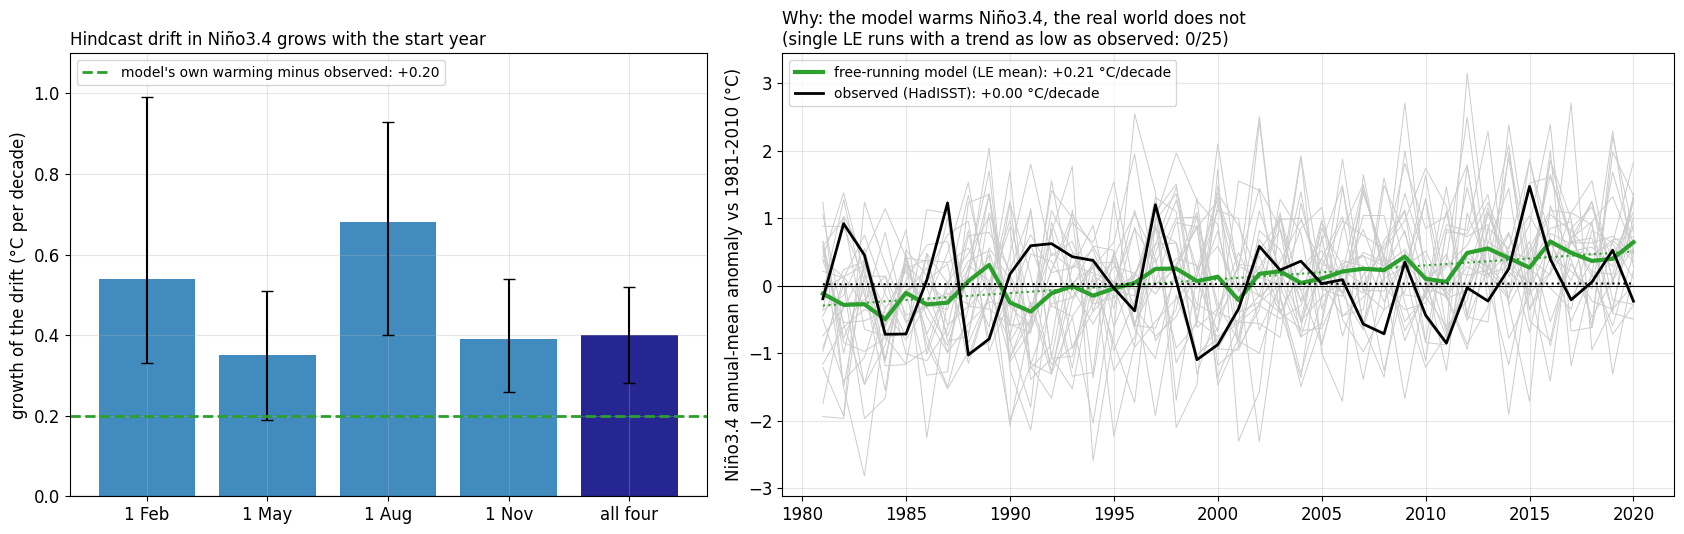

In [2]:
trend = read("04_start_months_and_year3_test", "drift_trend_all_start_months.csv")
forced = read("06_year3_drift_asymptote", "forced_vs_observed_trend.csv").set_index("index").loc["Nino3.4"]
row = trend[(trend["index"] == "Nino3.4") & trend["drift"].str.startswith("year 2")].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
labels = ["1 Feb", "1 May", "1 Aug", "1 Nov", "all four"]
vals = [float(row[f"{m} (°C/decade)"].split()[0]) for m in ("Feb", "May", "Aug", "Nov")] + [row["pooled (°C/decade)"]]
rng_ = [interval(row[f"{m} (°C/decade)"]) for m in ("Feb", "May", "Aug", "Nov")] + [interval(row["pooled 90%"])]
ax.bar(range(5), vals, color=["tab:blue"] * 4 + ["navy"], alpha=0.85)
ax.errorbar(range(5), vals, yerr=[[v - lo for v, (lo, hi) in zip(vals, rng_)], [hi - v for v, (lo, hi) in zip(vals, rng_)]],
            fmt="none", color="k", capsize=4)
ax.axhline(forced["β LE − β obs"], color="tab:green", ls="--", lw=2,
           label=f"model's own warming minus observed: {forced['β LE − β obs']:+.2f}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(5), labels)
ax.set_ylim(0, 1.1)
ax.set_ylabel("growth of the drift (°C per decade)")
ax.set_title("Hindcast drift in Niño3.4 grows with the start year", loc="left", fontsize=12)
ax.legend(fontsize=10, loc="upper left")

ax = axes[1]
ann = lambda s: s[(s.index.year >= 1981) & (s.index.year <= 2020)].groupby(lambda p: p.year).mean()
clim = lambda s: s.loc[1981:2010].mean()
em = ann(LE_N.mean(axis=1))
for c in LE_N.columns:
    m = ann(LE_N[c])
    ax.plot(m.index, m - clim(em), color="0.8", lw=0.7)
ob = ann(OBS)
for s, c, lab, w in ((em, "tab:green", "free-running model (LE mean)", 3), (ob, "k", "observed (HadISST)", 2)):
    b, a = np.polyfit(s.index, s.values, 1)
    ax.plot(s.index, s - clim(s), color=c, lw=w, label=f"{lab}: {10 * b:+.2f} °C/decade")
    ax.plot(s.index, a + b * s.index - clim(s), color=c, lw=1.5, ls=":")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Niño3.4 annual-mean anomaly vs 1981-2010 (°C)")
ax.set_title(f"Why: the model warms Niño3.4, the real world does not\n"
             f"(single LE runs with a trend as low as observed: {forced['members with a trend ≤ obs']})", loc="left", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
fig.tight_layout()
save(fig, "decision", "1_drift_trend_and_cause")
plt.show()

### Result 2. Only the trend correction (TrDC) forecasts better than the current approach

Two tests of each correction on starts it was not built from (`05`):
* **test in time:** built from the 1981-2008 starts, used to forecast the 2009-2018 starts (24 starts, all start
  months) - the situation of the 2026 forecast, which lies after all hindcasts;
* **cross-validation:** each 1981-2018 start forecast with a correction built from all other starts (90 starts).

Bars: typical Niño3.4 forecast error (RMSE) in forecast years 1 and 2; **lower is better**. A star marks a
difference from the current approach that is unlikely to be chance (90% bootstrap). Year 2 contains winter
2027/28 of the 2026 forecast.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/07_drift_correction_decision/figures/fig_decision_2_method_tests.png


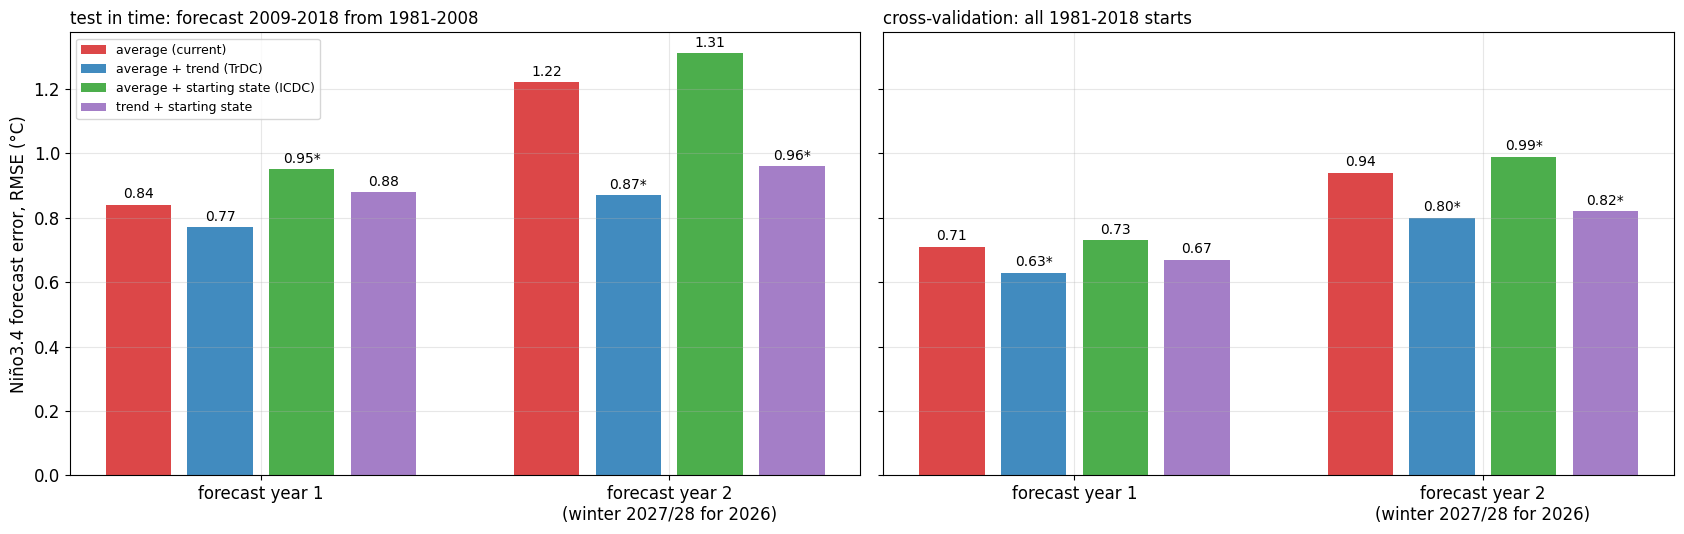

In [3]:
NAMES = {"MDC": "average\n(current)", "TrDC": "average + trend\n(TrDC)", "ICDC": "average + starting\nstate (ICDC)",
         "TrDC + ICDC": "trend + starting\nstate"}
COLS = {"MDC": "tab:red", "TrDC": "tab:blue", "ICDC": "tab:green", "TrDC + ICDC": "tab:purple"}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
for ax, (test, fname) in zip(axes, (("test in time: forecast 2009-2018 from 1981-2008", "test_in_time"),
                                    ("cross-validation: all 1981-2018 starts", "cross_validation"))):
    tab = read("05_drift_correction_methods", f"{fname}.csv")
    ci = read("05_drift_correction_methods", f"{fname}_ci.csv")
    for g, lab in enumerate(("year 1", "year 2")):
        sub = tab[(tab["index"] == "Nino3.4") & (tab["lead year"] == lab) & tab["starts"].str.startswith("all")].set_index("method")
        for k, m in enumerate(NAMES):
            x = g * 5 + k
            v = sub.loc[m, "RMSE (°C)"]
            ax.bar(x, v, color=COLS[m], alpha=0.85, label=NAMES[m].replace("\n", " ") if g == 0 else None)
            sig = m != "MDC" and ci[(ci["index"] == "Nino3.4") & (ci["lead year"] == lab) & (ci["method"] == m)
                                    & (ci["metric"] == "MSE")]["significant"].eq("yes").any()
            ax.text(x, v + 0.02, f"{v:.2f}" + ("*" if sig else ""), ha="center", fontsize=10)
    ax.set_xticks([1.5, 6.5], ["forecast year 1", "forecast year 2\n(winter 2027/28 for 2026)"])
    ax.set_title(test, loc="left", fontsize=12)
axes[0].set_ylabel("Niño3.4 forecast error, RMSE (°C)")
axes[0].legend(fontsize=9, loc="upper left")
fig.tight_layout()
save(fig, "decision", "2_method_tests")
plt.show()

In both tests the trend correction lowers the error, most in year 2 (test in time: 1.22 → 0.87 °C). Correcting
for the starting state (ICDC) does not help and makes the forecast worse; 2026 also starts from a stronger El Niño
(+2.5 °C) than any hindcast, so ICDC would extrapolate. **Decision: trend yes (TrDC), starting state no.** For
2026 the trend is held at the last start (2018) rather than extended 8 more years.

### Result 3. Year 3: the drift is still changing, so continue it ($r = 1$)

The hindcasts run 2 years, so the drift in year 3 of the 2026 forecast (Nov 2028 - Oct 2029) must be extended.

**Left: what the free-running large ensemble says.** Once a hindcast has forgotten its start, it should behave like
the model's own climate (the LE). The plot shows the remaining difference, LE minus hindcast, for the 1 Nov
starts, by forecast month. If the drift were levelling off, this gap would shrink towards zero and year 3 should
repeat year 2 ($r = 0$). Instead the gap *grows* through year 2: the hindcasts are still moving away from the
model's own climate when they stop. The drift will therefore keep changing in year 3 at least as fast as from
year 1 to year 2, i.e. $r \ge 1$ (the ratio of the year-2 to the year-1 gap is $r$ ≈ 1.6, 90% range 1.0-2.7; `06`).

**Right: the check in the forecast itself.** The jump of the 2026 forecast from Oct to Nov 2028 for each $r$.
Repeating the year-2 drift ($r = 0$, current) makes the forecast jump by +0.33 °C, an artefact; $r = 1$ removes
it. Larger $r$ (as the LE allows) would make a jump the other way, so **$r = 1$**.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/07_drift_correction_decision/figures/fig_decision_3_year3.png


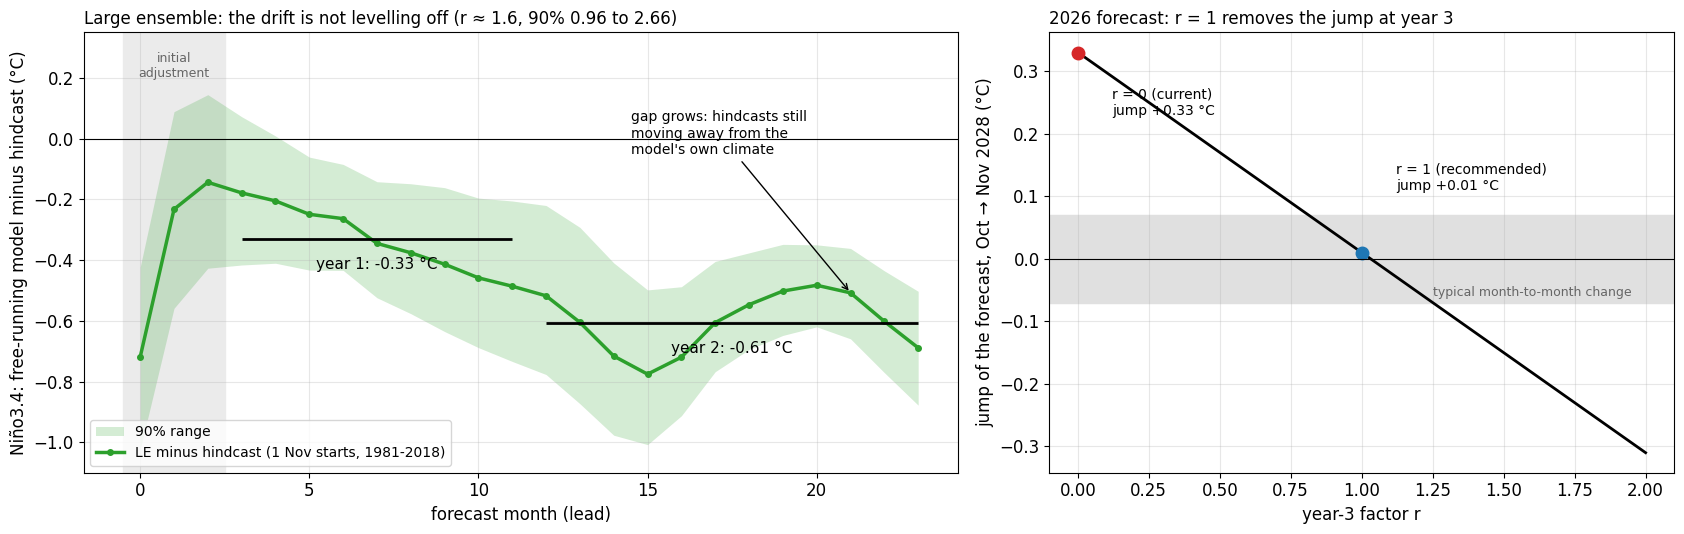

In [4]:
hc = np.nanmean(D["ref_nino"].sel(init=INIT).values, axis=1)        # (year, lead)
years = D["year"].values
tgt = lambda y, L: pd.Period(year=int(y), month=INIT, freq="M") + int(L)
le_mean = LE_N.mean(axis=1)
le = np.array([[le_mean[tgt(y, L)] for L in range(24)] for y in years])
G = le - hc
rng = np.random.default_rng(0)
Gb = np.array([G[rng.integers(0, len(years), len(years))].mean(0) for _ in range(N_BOOT)])
gap = read("06_year3_drift_asymptote", "year3_gap_r.csv")
gn = gap[(gap["index"] == "Nino3.4") & (gap["start"] == "Nov") & gap["base"].str.startswith("1981-2018")].iloc[0]
p05 = read("05_drift_correction_methods", "nov2026_la_nina_by_method.csv")
row = p05[(p05["index"] == "Nino3.4") & (p05["method"] == "TrDC, at 2018")].iloc[0]
steps = {float(re.findall(r"r = ([\d.]+)", c)[0]): row[c] for c in p05.columns if c.startswith("step")}

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
L = np.arange(24)
ax.fill_between(L, *np.percentile(Gb, [5, 95], axis=0), color="tab:green", alpha=0.2, lw=0, label="90% range")
ax.plot(L, G.mean(0), color="tab:green", lw=2.5, marker="o", ms=4, label="LE minus hindcast (1 Nov starts, 1981-2018)")
for sl, lab in ((slice(ADJUST_LEADS, 12), "year 1"), (slice(12, 24), "year 2")):
    m = G.mean(0)[sl].mean()
    ax.hlines(m, L[sl][0], L[sl][-1], color="k", lw=2)
    ax.text(L[sl].mean(), m - 0.06, f"{lab}: {m:+.2f} °C", ha="center", va="top", fontsize=11)
ax.axhline(0, color="k", lw=0.8)
ax.annotate("gap grows: hindcasts still\nmoving away from the\nmodel's own climate", xy=(21, G.mean(0)[21]), xytext=(14.5, -0.05),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.axvspan(-0.5, ADJUST_LEADS - 0.5, color="0.92", zorder=0)
ax.text(1, 0.24, "initial\nadjustment", ha="center", va="center", fontsize=9, color="0.4")
ax.set_ylim(-1.1, 0.35)
ax.set_xlabel("forecast month (lead)")
ax.set_ylabel("Niño3.4: free-running model minus hindcast (°C)")
ax.set_title(f"Large ensemble: the drift is not levelling off (r ≈ {gn['r = G2/G1']:.1f}, 90% {gn['r 90%']})", loc="left", fontsize=12)
ax.legend(fontsize=10, loc="lower left")

ax = axes[1]
rr = np.array(sorted(steps))
b, a = np.polyfit(rr, [steps[k] for k in rr], 1)
rx = np.linspace(0, 2, 50)
ax.plot(rx, a + b * rx, color="k", lw=2)
for r_, lab in ((0.0, "r = 0 (current)"), (1.0, "r = 1 (recommended)")):
    ax.plot(r_, steps[r_], "o", ms=9, color="tab:red" if r_ == 0 else "tab:blue")
    ax.annotate(f"{lab}\njump {steps[r_]:+.2f} °C", (r_, steps[r_]), xytext=(r_ + 0.12, steps[r_] + (-0.1 if r_ == 0 else 0.1)), fontsize=10)
ax.axhspan(-0.07, 0.07, color="0.88", zorder=0)
ax.text(1.95, -0.065, "typical month-to-month change", ha="right", va="bottom", fontsize=9, color="0.4")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("year-3 factor r")
ax.set_ylabel("jump of the forecast, Oct → Nov 2028 (°C)")
ax.set_title("2026 forecast: r = 1 removes the jump at year 3", loc="left", fontsize=12)
fig.tight_layout()
save(fig, "decision", "3_year3")
plt.show()

(A third estimate, from combining start months six months apart (`04`), gave $r \approx 0.2$; it rests on the
assumption that the drift does not depend on the start month, which does not hold well, and it leaves the
+0.27 °C jump. Both the LE and the continuity check rule it out.)

### Result 4. What each choice gives for 2026

Fraction of the 30 members of the 1 Nov 2026 forecast with a La Niña (Niño3.4 DJF mean ≤ −0.5 °C) in winter
2027/28, winter 2028/29 and both, for each construction. The black lines show the sampling uncertainty of a
30-member fraction (±0.08). Hatched: ICDC's year 3 is not usable (its starting-state term would be carried
through a whole extra year).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/07_drift_correction_decision/figures/fig_decision_4_p_la_nina_by_construction.png


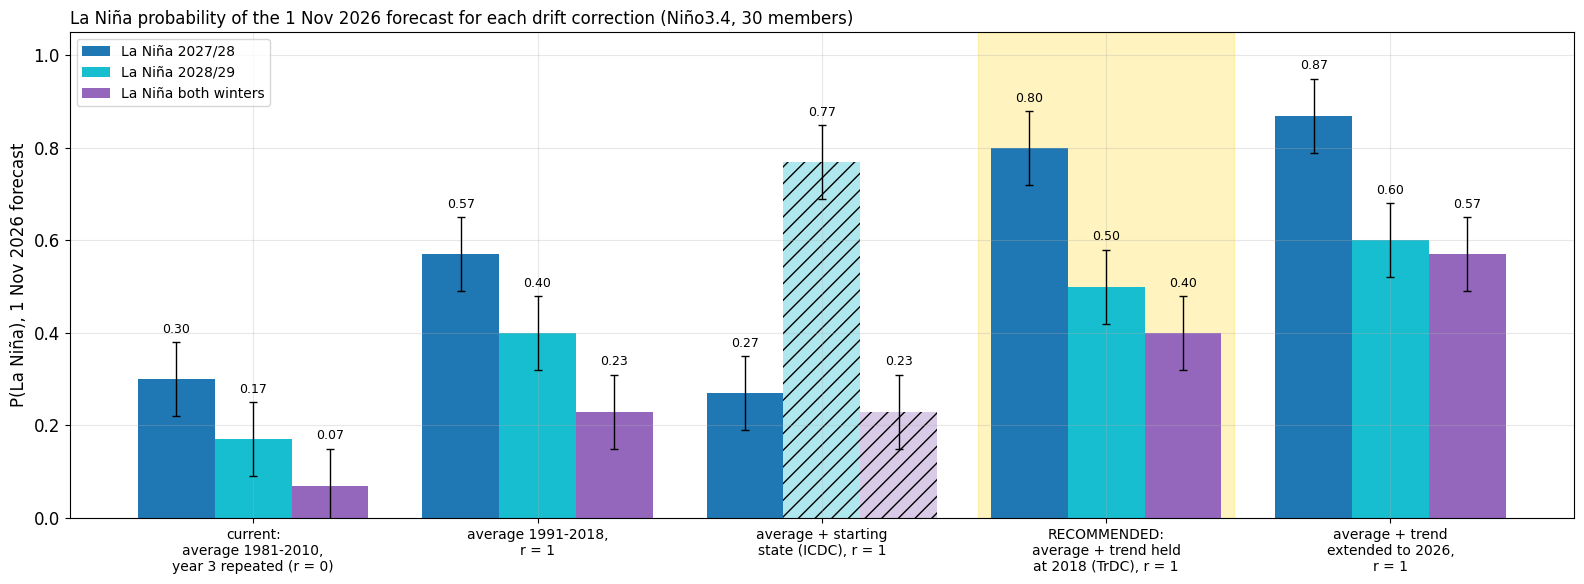

In [5]:
r01 = read("01_year3_drift_sensitivity", "year3_la_nina_probabilities.csv")
cur = r01[(r01["index"] == "Niño3.4") & (r01["base"] == "1981-2010") & (r01["method"] == "hold (r = 0)")].iloc[0]
r03 = read("03_drift_trend_and_test", "nov2026_la_nina_by_drift_method.csv")
f91 = r03[(r03["index"] == "Nino3.4") & (r03["method"] == "fixed 1991-2018")].iloc[0]
rows = [("current:\naverage 1981-2010,\nyear 3 repeated (r = 0)", cur["P(LN 27/28)"], cur["P(LN 28/29)"], cur["P(both)"]),
        ("average 1991-2018,\nr = 1", f91["P(LN 27/28)"], f91["P(LN 28/29)"], f91["P(both)"])]
for m, lab in (("ICDC", "average + starting\nstate (ICDC), r = 1"),
               ("TrDC, at 2018", "RECOMMENDED:\naverage + trend held\nat 2018 (TrDC), r = 1"),
               ("TrDC, at 2026", "average + trend\nextended to 2026,\nr = 1")):
    r_ = p05[(p05["index"] == "Nino3.4") & (p05["method"] == m)].iloc[0]
    rows.append((lab, r_["P(LN 27/28)"], r_["P(LN 28/29), r = 1"], r_["P(both), r = 1"]))
cand = pd.DataFrame(rows, columns=["construction", "La Niña 2027/28", "La Niña 2028/29", "La Niña both winters"])

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(cand))
icdc = int(np.where(cand["construction"].str.contains("ICDC"))[0][0])
rec = int(np.where(cand["construction"].str.startswith("RECOMMENDED"))[0][0])
ax.axvspan(rec - 0.45, rec + 0.45, color="gold", alpha=0.25, zorder=0)
for k, (col, c) in enumerate(zip(cand.columns[1:], ["tab:blue", "tab:cyan", "tab:purple"])):
    bars = ax.bar(x + (k - 1) * 0.27, cand[col], 0.27, color=c, label=col, yerr=0.08, capsize=3, error_kw={"lw": 1})
    for i, b_ in enumerate(bars):
        ax.text(b_.get_x() + b_.get_width() / 2, cand[col].iloc[i] + 0.1, f"{cand[col].iloc[i]:.2f}", ha="center", fontsize=9)
    if k > 0:
        bars[icdc].set_hatch("//"), bars[icdc].set_alpha(0.35)
ax.set_xticks(x, cand["construction"], fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel("P(La Niña), 1 Nov 2026 forecast")
ax.set_title("La Niña probability of the 1 Nov 2026 forecast for each drift correction (Niño3.4, 30 members)", loc="left", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
fig.tight_layout()
save(fig, "decision", "4_p_la_nina_by_construction")
plt.show()
cand.assign(construction=cand["construction"].str.replace("\n", " ")).to_csv(DATA_DIR / "nov2026_p_la_nina_by_construction.csv", index=False)

### Result 4b. How much does the trend correction depend on the starts it is fitted on?

The recommended TrDC fits the average and the trend on all 1981-2018 starts. Here the same correction (trend held
at 2018, $r = 1$) is fitted on windows that start later and all end in 2018 (`03`, section 3c); a shorter window
also means fewer starts for the trend (38 for 1981-2018, 15 for 2004-2018). The current approach is shown for
reference. Black lines: ±0.08 sampling uncertainty of a 30-member fraction.

* **Winter 2027/28 does not depend on the window:** P(La Niña) 0.80-0.83 for every window.
* **Winter 2028/29 does:** 0.50 with all starts, 0.60-0.73 with the later windows (both winters: 0.40 against
  0.50-0.63). The full record is the low end, not an outlier.
* **Why the full record is kept** (`03`, section 3d, test in time: built from windows ending in 2008, verified on
  2009-2018): it forecasts year 1 best; the later windows over-correct year 1 (too cold, significantly worse) and
  are only slightly better in year 2. The model's own forced Niño3.4 warming (LE mean) is the same, about
  +0.2 °C per decade, in every window, so there is no physical reason to drop the early starts; doing so mainly
  makes the trend noisier. The later windows give a supported upper end for winter 2028/29.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/07_drift_correction_decision/figures/fig_decision_4b_p_la_nina_trdc_by_training_starts.png


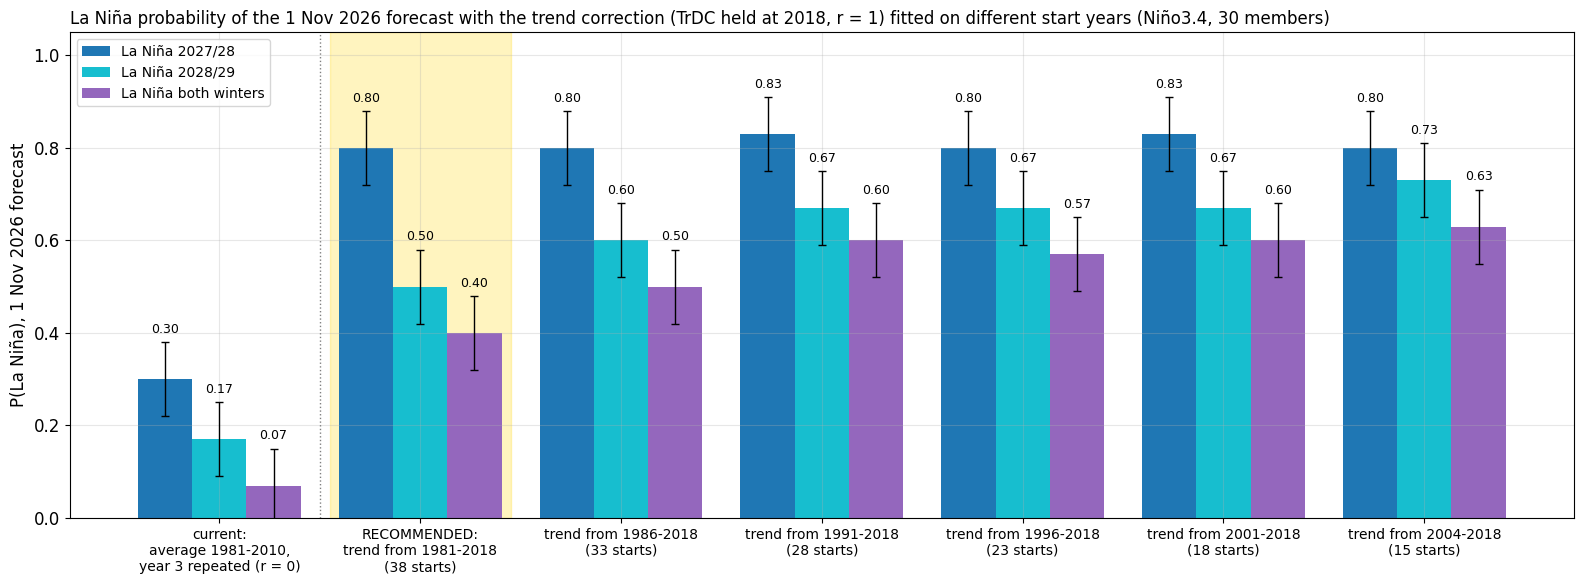

In [6]:
trw = read("03_drift_trend_and_test", "nov2026_la_nina_trdc_by_training_starts.csv")
trw = trw[trw["index"] == "Nino3.4"]
rows = [("current:\naverage 1981-2010,\nyear 3 repeated (r = 0)", cur["P(LN 27/28)"], cur["P(LN 28/29)"], cur["P(both)"])]
for _, r_ in trw.iterrows():
    win = r_["trend starts"].split()[0]
    lab = (f"RECOMMENDED:\ntrend from {win}\n({r_['starts']} starts)" if "recommended" in r_["trend starts"]
           else f"trend from {win}\n({r_['starts']} starts)")
    rows.append((lab, r_["P(LN 27/28)"], r_["P(LN 28/29)"], r_["P(both)"]))
cand_w = pd.DataFrame(rows, columns=["construction", "La Niña 2027/28", "La Niña 2028/29", "La Niña both winters"])

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(cand_w))
rec = int(np.where(cand_w["construction"].str.startswith("RECOMMENDED"))[0][0])
ax.axvspan(rec - 0.45, rec + 0.45, color="gold", alpha=0.25, zorder=0)
for k, (col, c) in enumerate(zip(cand_w.columns[1:], ["tab:blue", "tab:cyan", "tab:purple"])):
    bars = ax.bar(x + (k - 1) * 0.27, cand_w[col], 0.27, color=c, label=col, yerr=0.08, capsize=3, error_kw={"lw": 1})
    for i, b_ in enumerate(bars):
        ax.text(b_.get_x() + b_.get_width() / 2, cand_w[col].iloc[i] + 0.1, f"{cand_w[col].iloc[i]:.2f}", ha="center", fontsize=9)
ax.axvline(0.5, color="0.5", lw=1, ls=":")
ax.set_xticks(x, cand_w["construction"], fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel("P(La Niña), 1 Nov 2026 forecast")
ax.set_title("La Niña probability of the 1 Nov 2026 forecast with the trend correction (TrDC held at 2018, r = 1) "
             "fitted on different start years (Niño3.4, 30 members)", loc="left", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
fig.tight_layout()
save(fig, "decision", "4b_p_la_nina_trdc_by_training_starts")
plt.show()
cand_w.assign(construction=cand_w["construction"].str.replace("\n", " ")).to_csv(
    DATA_DIR / "nov2026_p_la_nina_trdc_by_training_starts.csv", index=False)

### Conclusion

**Decision.** Build the lead-time dependent climatology from all 1981-2018 hindcast starts as the average drift
**plus a linear trend over the start years (TrDC), held at the last start (2018)**; no correction for the starting
state; in year 3, continue the year-1-to-2 drift change ($r = 1$) with the trend part held; anomalies from the
observed 1991-2020 climatology (whose difference from 1981-2010 is only +0.02-0.06 °C in Niño3.4 and does not
change the result).

| 1 Nov 2026, P(La Niña) | winter 2027/28 | winter 2028/29 | both |
|---|---|---|---|
| **recommended** | **0.80** | **0.50** | **0.40** |
| current | 0.30 | 0.17 | 0.07 |
| range of the defensible alternatives | 0.57 - 0.87 | 0.40 - 0.60 | 0.23 - 0.57 |

**What could make it wrong.** The trend correction assumes the model keeps warming Niño3.4 relative to the
real world, as it has since 1981 (the LE says the model keeps warming through 2029). If the real equatorial
Pacific starts warming too, the correction is too strong. On the other hand, even with the trend the 2009-2018
forecasts were still too warm in year 2 (+0.4 °C), so it may also be too weak. Winter 2028/29 has no hindcasts
behind it and is the least certain.

**Next steps.** Apply the same correction to maps (a per-gridpoint trend in `rc.matched_climatology`) and check the
drift trend outside Niño3.4; a few 36-month hindcasts would test year 3 directly.